In [2]:
import numpy as np
from matplotlib import pyplot as plt

In [3]:
k = np.random.randint(-5, 5)
b = np.random.randint(-5, 5)

def y_true(x):
    return k * x + b

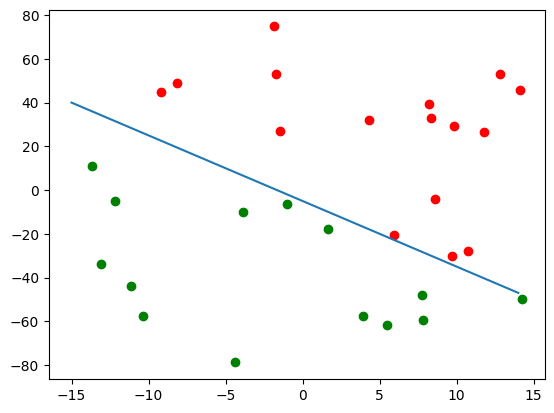

In [4]:
count = 30

x_tr = np.array([i for i in range(- int(count / 2), int(count / 2), 1)])
y_tr = y_true(x_tr)

x_test_1 = np.array([])
y_test_1 = np.array([])

x_test_2 = np.array([])
y_test_2 = np.array([])

rng = np.random.default_rng(seed=42)
x_train = rng.uniform(-15, 15, size=count)
y_train = rng.uniform(-80, 80, size=count)

for i in range(count):
    if y_train[i] > y_true(x_train[i]):
        x_test_1 = np.append(x_test_1, x_train[i])
        y_test_1 = np.append(y_test_1, y_train[i])
    else:
        x_test_2 = np.append(x_test_2, x_train[i])
        y_test_2 = np.append(y_test_2, y_train[i])

plt.plot(x_tr, y_tr)
plt.scatter(x_test_1, y_test_1, color='r')
plt.scatter(x_test_2, y_test_2, color='g')
plt.show()

Первый вариант, через аналитическую фматричную формулу.

18.293343408261368 -4.509052838807215


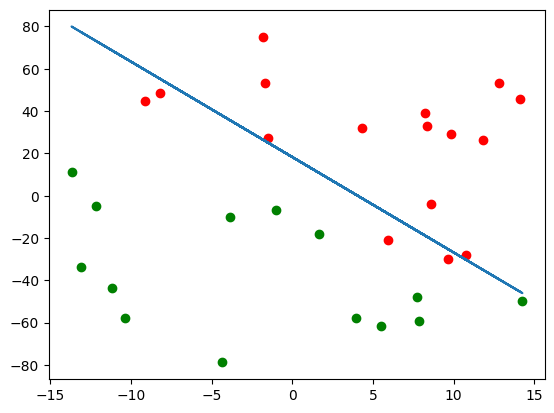

In [5]:
X = np.array(np.ones(30))
X_test = np.concatenate((x_test_1, x_test_2))
X = np.append(X, X_test)
Y_test = np.concatenate((y_test_1, y_test_2))

X = X.reshape(2, 30).transpose()
n = np.array([k, b])
labels = np.array([])
for i in range(30):
    labels = np.append(labels, n @ np.array([X_test[i], Y_test[i]]))

solution = np.linalg.inv(X.T @ X) @ X.T @ labels

def y_sol(w0, w1, x):
    return w0*x + w1

print(solution[0], solution[1])

plt.plot(X.T[1], y_sol(X.T[1], solution[0], solution[1]))
plt.scatter(x_test_1, y_test_1, color='r')
plt.scatter(x_test_2, y_test_2, color='g')
plt.show()

Добавление регуляризации

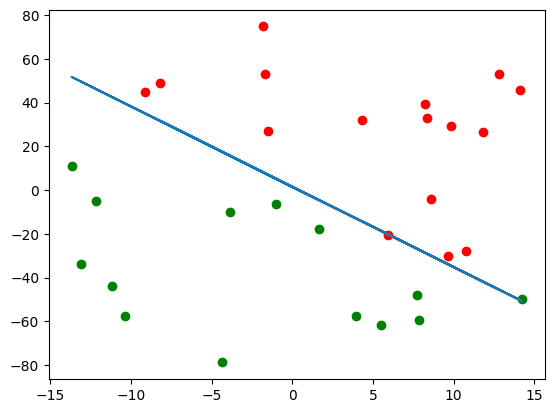

In [6]:
X = np.array(np.ones(30))
X_test = np.concatenate((x_test_1, x_test_2))
X = np.append(X, X_test)
Y_test = np.concatenate((y_test_1, y_test_2))

X = X.reshape(2, 30).transpose()
n = np.array([k, b])
labels = np.array([])
for i in range(30):
    labels = np.append(labels, n @ np.array([X_test[i], Y_test[i]]))

lambda_c = 300

solution = np.linalg.inv(X.T @ X + lambda_c * np.eye(2)) @ X.T @ labels

def y_sol(w0, w1, x):
    return w0*x + w1

plt.plot(X.T[1], y_sol(X.T[1], solution[0], solution[1]))
plt.scatter(x_test_1, y_test_1, color='r')
plt.scatter(x_test_2, y_test_2, color='g')
plt.show()

In [36]:
higher_degre = 5
all_coef = np.array([np.random.randint(-5, 5) for coef in range(higher_degre)])

def polinom_true(x: float, coeff, degree: int) -> float:
    y = 0
    for i in range(degree):
         y += coeff[i] * x ** i
    return y

def polinom_deriv_true(x, coeff, degree):
    y = 0
    for i in range(1, degree):
         y += i * coeff[i] * x ** (i - 1)
    return y

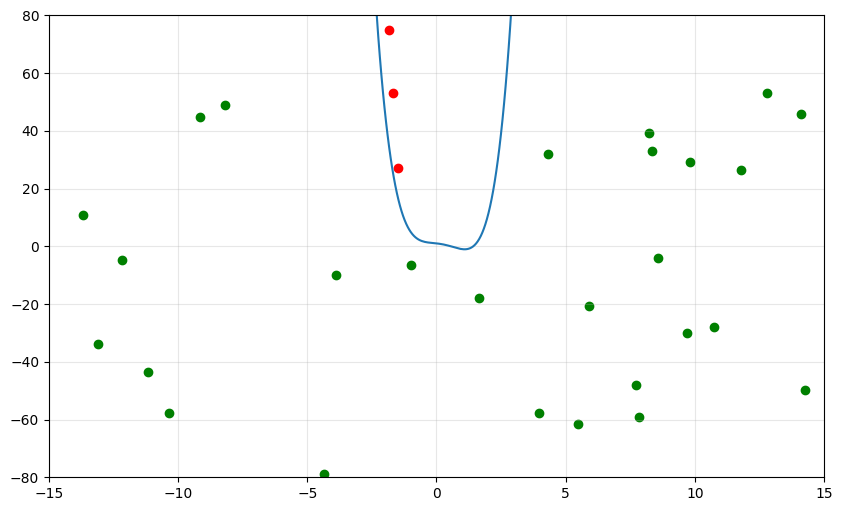

In [37]:
count = 30

x_tr = np.array([i for i in range(- int(count / 2), int(count / 2), 1)])
y_tr = polinom_true(x_tr, all_coef, higher_degre)

x_test_1 = np.array([])
y_test_1 = np.array([])

x_test_2 = np.array([])
y_test_2 = np.array([])

rng = np.random.default_rng(seed=42)
x_train = rng.uniform(-15, 15, size=count)
y_train = rng.uniform(-80, 80, size=count)

for i in range(count):
    x = x_train[i]
    y = y_train[i]

    point_on_curve = np.array([
        x,
        polinom_true(x, all_coef, higher_degre),
    ])
    normal = np.array([
        -polinom_deriv_true(x, all_coef, higher_degre),
        1,
    ])

    displacement = np.array([x, y]) - point_on_curve

    if normal @ displacement > 0:
        x_test_1 = np.append(x_test_1, x)
        y_test_1 = np.append(y_test_1, y)
    else:
        x_test_2 = np.append(x_test_2, x)
        y_test_2 = np.append(y_test_2, y)

x_plot = np.linspace(-15, 15, 500)
y_plot = polinom_true(x_plot, all_coef, higher_degre)

plt.figure(figsize=(10, 6))

plt.plot(x_plot, y_plot)
plt.scatter(x_test_1, y_test_1, color='r')
plt.scatter(x_test_2, y_test_2, color='g')

plt.xlim(-15, 15)
plt.ylim(-80, 80)
plt.grid(alpha=0.3)
plt.show()

Тут какая-то хуйня при минимизации функционала вида Q(w) = $\sum X \cdot \omega - Y$, все классифифцирует с точностью до знака, что по сути значит что ниче не работает

Спуск ошибка: 28717.88385399455 неверных классов: 16
МНК напрямую ошибка: 5.666367684700549 неверных классов: 1


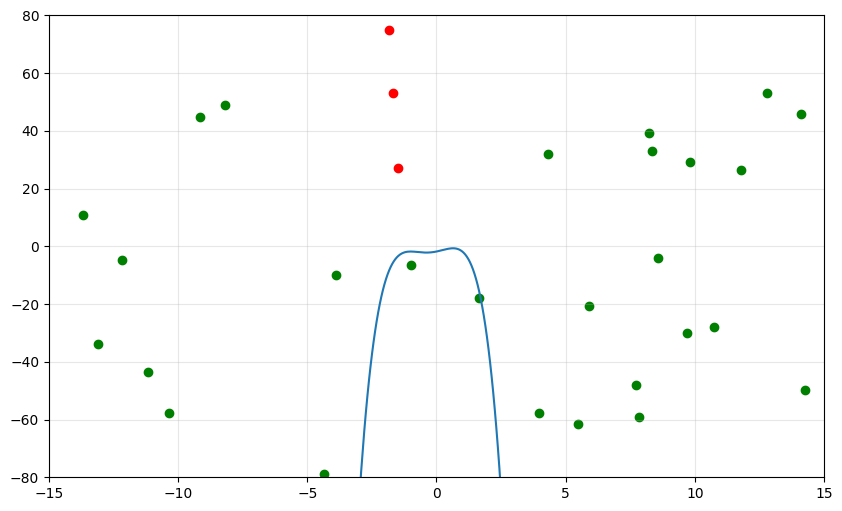

In [38]:
def get_labels(all_coef, higher_degre, x_train, y_train):

    lab = np.array([])
    for i in range(len(x_train)):
        x = x_train[i]
        y = y_train[i]

        point_on_curve = np.array([
            x,
            polinom_true(x, all_coef, higher_degre),
        ])
        normal = np.array([
            -polinom_deriv_true(x, all_coef, higher_degre),
            1,
        ])

        displacement = np.array([x, y]) - point_on_curve

        if normal @ displacement > 0:
            lab = np.append(lab, 1)
        else:
            lab = np.append(lab, -1)

    return lab

def solution(w_f_it, higher_degre, x_vec, y_vec, X_mat, error = 1e-5):
    labeles = get_labels(all_coef, higher_degre, x_vec, y_vec)
    learning_rate = 0.5 / np.linalg.norm(X_mat, 2)**2

    w_f_it -= 2 * learning_rate * X_mat.T @ (X_mat @ w_f_it.T - labeles)

    count_itter = 0
    while np.linalg.norm(X_mat @ w_f_it.T - labeles)**2 > error and count_itter < 100000:
        w_f_it -= 2 * learning_rate * X_mat.T @ (X_mat @ w_f_it.T - labeles)
        first_itter = np.linalg.norm(X_mat @ w_f_it.T - labeles)**2
        count_itter += 1

    return w_f_it

w_ = np.ones(higher_degre+1)

X_2 = np.array([])

for i in range(higher_degre):
    X_test = np.concatenate((x_test_1**i, x_test_2**i))
    X_2 = np.append(X_2, X_test)

Y = np.concatenate((y_test_1, y_test_2))
X = np.concatenate((x_test_1, x_test_2))
X_2 = np.append(X_2, Y)
X_2 = X_2.reshape(higher_degre+1, 30).transpose()

Y_2 = np.array([])

# print(X, Y)
result = solution(w_, higher_degre, X, Y, X_2)
labels = get_labels(all_coef, higher_degre, X, Y)
reference = np.linalg.lstsq(X_2, labels, rcond=None)[0]

for name, weights in [("Спуск", result), ("МНК напрямую", reference)]:
    scores = X_2 @ weights
    loss = np.sum((scores - labels)**2)
    mistakes = np.count_nonzero(np.sign(scores) != labels)
    print(name, "ошибка:", loss, "неверных классов:", mistakes)

# print(result)

x_plot = np.linspace(-15, 15, 500)
y_plot = polinom_true(x_plot, all_coef, higher_degre)

plt.figure(figsize=(10, 6))
y_boundary = (
    polinom_true(x_plot, -np.sign(result[::-1]), higher_degre)
    / result[-1]
)

plt.plot(x_plot, y_boundary)
plt.scatter(x_test_1, y_test_1, color='r')
plt.scatter(x_test_2, y_test_2, color='g')

plt.xlim(-15, 15)
plt.ylim(-80, 80)
plt.grid(alpha=0.3)
plt.show()
